In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [3]:
data = pd.read_csv("House_Price_dataset.csv")
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,yes,no,no,no,yes,2.0,yes,furnished
1,12250000,8960,4.0,4.0,4.0,yes,no,no,no,yes,3.0,no,furnished
2,12250000,9960,3.0,2.0,2.0,yes,no,yes,no,no,2.0,yes,semi-furnished
3,12215000,7500,4.0,2.0,2.0,yes,no,yes,no,yes,3.0,yes,furnished
4,11410000,7420,4.0,1.0,2.0,yes,yes,yes,no,yes,2.0,no,furnished


In [4]:
print("Shape:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())

Shape: (545, 13)

Missing values:
price               0
area                0
bedrooms            5
bathrooms           5
stories             2
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             4
prefarea            0
furnishingstatus    0
dtype: int64


In [5]:
data.fillna(data.mean(numeric_only=True), inplace=True)

In [6]:
print("\nMissing values:")
print(data.isnull().sum())


Missing values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [7]:
categorical_columns = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea",
    "furnishingstatus"
]

In [8]:
for column in categorical_columns:
    data[column] = data[column].astype("category").cat.codes

data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,2.0,1,0
1,12250000,8960,4.0,4.0,4.0,1,0,0,0,1,3.0,0,0
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,2.0,1,1
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,3.0,1,0
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,2.0,0,0


In [9]:
x = data[["area"]]
y = data["price"]

In [10]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=0
)

In [11]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (436, 1)
Testing data: (109, 1)


In [12]:
regs = LinearRegression()


In [13]:
regs.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [14]:
prediction = regs.predict(x_test)

In [15]:
mse = mean_squared_error(y_test, prediction)
mae = mean_absolute_error(y_test, prediction)
r2 = r2_score(y_test, prediction)

In [16]:
print("Linear Regression")
print("Coefficient:",regs.coef_)
print("Intercept:",regs.intercept_)
print("MSE:",mse)
print("MAE:",mae)
print("R2:",r2)

Linear Regression
Coefficient: [475.26784571]
Intercept: 2329244.9134951513
MSE: 1997672371756.0867
MAE: 1026553.7662016952
R2: 0.3067292122216637


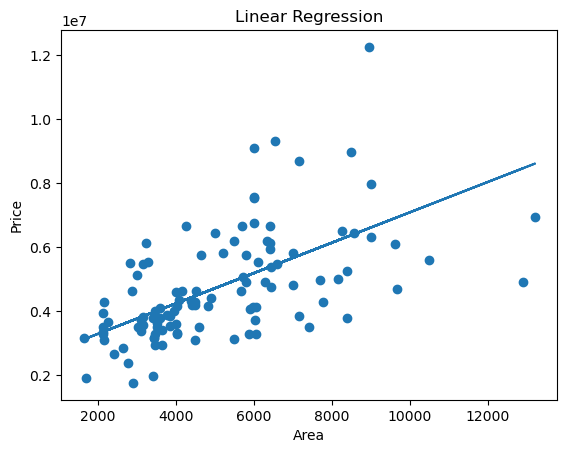

In [17]:
plt.scatter(x_test, y_test)
plt.plot(x_test, prediction)

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Linear Regression")

plt.show()

In [18]:
poly = PolynomialFeatures(degree=2)

In [19]:
x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.transform(x_test)

In [20]:
poly_regs = LinearRegression()

In [21]:
poly_regs.fit(x_train_poly, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [22]:
poly_pred = poly_regs.predict(x_test_poly)

In [23]:
poly_mse = mean_squared_error(y_test, poly_pred)
poly_mae = mean_absolute_error(y_test, poly_pred)
poly_r2 = r2_score(y_test, poly_pred)

In [24]:
print("Polynomial Regression (Degree 2)")
print("Coefficient:",poly_regs.coef_)
print("Intercept:",poly_regs.intercept_)
print("MSE:",poly_mse)
print("MAE:",poly_mae)
print("R2:",poly_r2)

Polynomial Regression (Degree 2)
Coefficient: [ 0.00000000e+00  1.06854348e+03 -4.45116604e-02]
Intercept: 657457.2751193284
MSE: 1910061216759.3765
MAE: 1023868.0932975559
R2: 0.33713372464396163


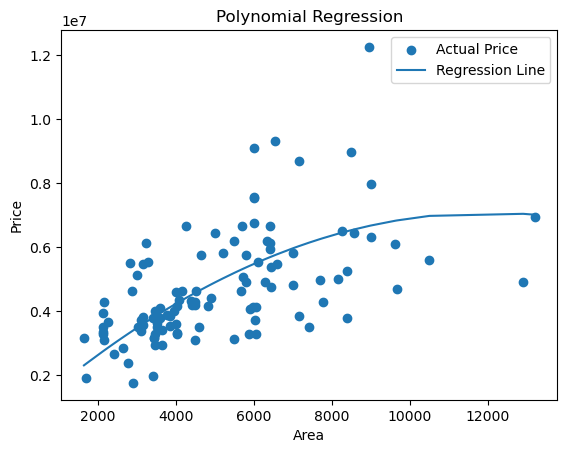

In [25]:
plt.scatter(x_test, y_test, label="Actual Price")

x_sorted = x_test.sort_values(by="area")
x_sorted_poly = poly.transform(x_sorted)
y_sorted_pred = poly_regs.predict(x_sorted_poly)

plt.plot(x_sorted, y_sorted_pred, label="Regression Line")

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Polynomial Regression")
plt.legend()
plt.show()

In [26]:
print("Analysis:")
flag = ""
if poly_r2 > r2:
    flag = "polynomial"
    best_model = poly_regs
    print("Polynomial Regression has the higher R2 score")
else:
    flag = "linear"
    best_model = regs
    print("Linear Regression has the higher R2 score")

Analysis:
Polynomial Regression has the higher R2 score


In [27]:
get_area = float(input("Enter the area of the house: "))

if flag == "polynomial":
    print("Polynomial")
    area_input = poly.transform([[get_area]])
    pred_price = poly_regs.predict(area_input)[0]
else:
    print("Linear")
    pred_price = regs.predict([[get_area]])[0]

print("Predicted Price:", round(pred_price, 2))

Enter the area of the house:  7421


Polynomial
Predicted Price: 6135806.06


F:\setup\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


In [28]:
features = [
    "area",
    "bathrooms",
    "bedrooms",
    "stories",
    "mainroad",
    "guestroom",
    "airconditioning",
    "parking",
    "prefarea"
]

In [29]:
x = data[features]
y = data["price"]

In [30]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.30,
    random_state=0
)

In [31]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (381, 9)
Testing data: (164, 9)


In [32]:
lreg = LinearRegression()
lreg.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [33]:
lpred = lreg.predict(x_test)

In [34]:
lmse = mean_squared_error(y_test, lpred)
lmae = mean_absolute_error(y_test, lpred)
lr2 = r2_score(y_test, lpred)

In [35]:
print("Linear Regression")
print("Coefficient:",lreg.coef_)
print("Intercept:",lreg.intercept_)
print("MSE:", lmse)
print("MAE:", lmae)
print("R2:", lr2)

Linear Regression
Coefficient: [2.44810723e+02 1.03131855e+06 2.35141963e+05 3.67996456e+05
 5.04126879e+05 5.54570614e+05 8.57338542e+05 3.01123727e+05
 7.32389837e+05]
Intercept: -362661.03079674114
MSE: 965480135526.43
MAE: 746975.0809347159
R2: 0.7216653531835364


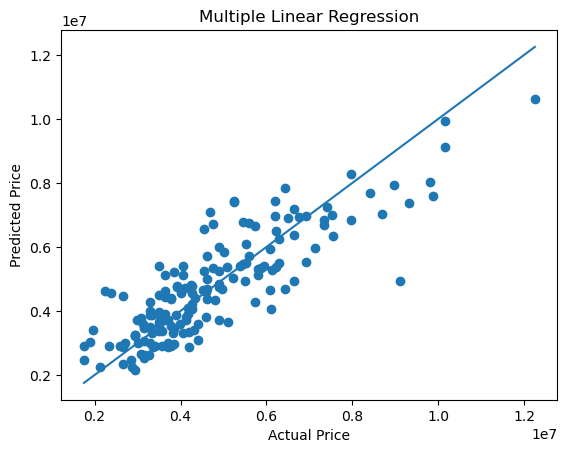

In [38]:
plt.scatter(y_test, lpred)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()])
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Multiple Linear Regression")

plt.show()

In [37]:
poly2 = PolynomialFeatures(degree=2)

In [41]:
x_train_poly = poly2.fit_transform(x_train)
x_test_poly = poly2.transform(x_test)

In [42]:
preg = LinearRegression()
preg.fit(x_train_poly, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [43]:
ppred = preg.predict(x_test_poly)

In [44]:
pmse = mean_squared_error(y_test, ppred)
pmae = mean_absolute_error(y_test, ppred)
pr2 = r2_score(y_test, ppred)

print("Polynomial Regression(2)")
print("Coefficient:",preg.coef_)
print("Intercept:",preg.intercept_)
print("MSE:", pmse)
print("MAE:", pmae)
print("R2:", pr2)

Polynomial Regression(2)
Coefficient: [ 8.06918031e-04  3.58830403e+02 -8.68145998e+05  8.60692456e+05
  6.47744789e+05 -1.16065067e+05  6.38721198e+05  1.11586350e+05
 -1.02733569e+06 -4.71018400e+05 -3.51697926e-02  1.22181317e+02
  2.92381677e+01 -7.36448892e+01  1.99382311e+02 -8.26849685e+01
  8.24411394e+01  1.96360903e+00  9.75609086e-01  3.32638983e+04
  1.55770272e+05  1.02472979e+04 -6.43514215e+03 -4.19043588e+05
  2.11786162e+05  3.47217518e+05  7.46662155e+05 -9.43028101e+04
 -9.33816449e+04 -2.25028532e+05  3.12393541e+05 -2.05571893e+05
  1.77376060e+05 -2.78399180e+05  1.16656013e+04  1.26205430e+05
 -4.43385707e+05  2.34881010e+05  5.87639261e+04  2.64530313e+05
 -1.16065071e+05  5.98896723e+05 -1.69591535e+05  9.22741563e+05
  1.27459353e+06  6.38721193e+05  4.70647119e+05  1.24541496e+04
 -1.21262650e+06  1.11586339e+05  1.04094903e+05  1.29225437e+04
 -3.16911767e+05 -3.02088605e+04 -4.71018386e+05]
Intercept: 240836.3096294375
MSE: 1264738319512.3916
MAE: 845593.63

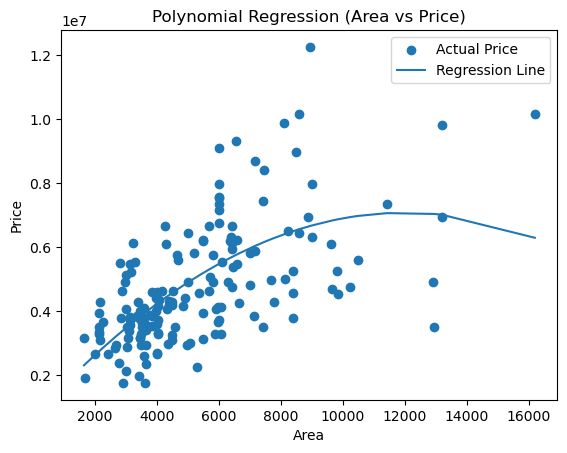

In [45]:
plt.scatter(x_test["area"], y_test, label="Actual Price")

x_sorted = x_test[["area"]].sort_values(by="area")
x_sorted_poly = poly.transform(x_sorted)
y_sorted_pred = poly_regs.predict(x_sorted_poly)

plt.plot(x_sorted["area"], y_sorted_pred, label="Regression Line")

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Polynomial Regression (Area vs Price)")
plt.legend()
plt.show()

In [46]:
print("Analysis:")
flag = ""
if pr2 > lr2:
    flag = "polynomial"
    best_model = preg
    print("Polynomial Regression has the higher R2 score")
else:
    flag = "linear"
    best_model = lreg
    print("Linear Regression has the higher R2 score")

Analysis:
Linear Regression has the higher R2 score


In [47]:
print("Enter the house details:")

user_area = float(input("Area: "))
user_bathrooms = float(input("Bathrooms: "))
user_bedrooms = float(input("Bedrooms: "))
user_stories = float(input("Stories: "))
user_mainroad = int(input("Mainroad (yes=1, no=0): "))
user_guestroom = int(input("Guestroom (yes=1, no=0): "))
user_airconditioning = int(input("Airconditioning (yes=1, no=0): "))
user_parking = float(input("Parking spaces: "))
user_prefarea = int(input("Preferred area (yes=1, no=0): "))

user_input = pd.DataFrame([[
    user_area,
    user_bathrooms,
    user_bedrooms,
    user_stories,
    user_mainroad,
    user_guestroom,
    user_airconditioning,
    user_parking,
    user_prefarea
]], columns=features)

if flag == "polynomial":
    print("polynomial")
    user_input_poly = poly2.transform(user_input)
    pred_price =best_model.predict(user_input_poly)[0]
else:
    print("Linear")
    pred_price = best_model.predict(user_input)[0]

print("Predicted House Price:", round(pred_price, 2))

Enter the house details:


Area:  7421
Bathrooms:  4
Bedrooms:  3
Stories:  3
Mainroad (yes=1, no=0):  1
Guestroom (yes=1, no=0):  0
Airconditioning (yes=1, no=0):  1
Parking spaces:  2
Preferred area (yes=1, no=0):  1


Linear
Predicted House Price: 10084871.49
